In [ ]:
import numpy as np
import emcee
from scipy.integrate import quad
import matplotlib.pyplot as plt
import pandas as pd
file_path=r"File path of data saved on your computer.csv"
data=pd.read_csv(file_path)

print(data.head())
print(data.columns)
print(data.shape)


             CID  IDSURVEY      zHD   zHDERR     zCMB  zCMBERR     zHEL  \
0         2011fe        51  0.00122  0.00084  0.00122  0.00002  0.00082   
1         2011fe        56  0.00122  0.00084  0.00122  0.00002  0.00082   
2         2012cg        51  0.00256  0.00084  0.00256  0.00002  0.00144   
3         2012cg        56  0.00256  0.00084  0.00256  0.00002  0.00144   
4  1994DRichmond        50  0.00299  0.00084  0.00299  0.00004  0.00187   

   zHELERR  m_b_corr  m_b_corr_err_DIAG  ...  PKMJDERR  NDOF   FITCHI2  \
0  0.00002   9.74571           1.516210  ...    0.1071    36   26.8859   
1  0.00002   9.80286           1.517230  ...    0.0579   101   88.3064   
2  0.00002  11.47030           0.781906  ...    0.0278   165  233.5000   
3  0.00002  11.49190           0.798612  ...    0.0667    55  100.1220   
4  0.00004  11.52270           0.880798  ...    0.0522   146  109.8390   

    FITPROB  m_b_corr_err_RAW  m_b_corr_err_VPEC  biasCor_m_b  biasCorErr_m_b  \
0  0.864470            

In [ ]:
z=data["zHD"]
mu_obs=data["MU_SH0ES"]
mu_err=data["MU_SH0ES_ERR_DIAG"]

In [ ]:
def E_XCDM(z,omega_m,w):
    return np.sqrt(
        omega_m*(1+z)**3+(1-omega_m)*(1+z)**(3*(1+w))
        )

In [ ]:
def luminosity_distance_XCDM(z, omega_m,w,H0=70):
    integral,error=quad(
        lambda zp:1/E_XCDM(zp,omega_m,w),
        0,
        z

    )
    c=299792.458
    D_C=(c/H0)*integral
    D_L=(1+z)*D_C
    return D_L

In [ ]:
def distance_modulus_XCDM(z,omega_m,w,H0=70):
    D_L=luminosity_distance_XCDM(z,omega_m,w,H0)
    mu=5*np.log10(D_L)+25

    return mu

In [ ]:
def log_likelihood_XCDM(theta):
    omega_m=theta[0]
    w=theta[1]

    DL_values=[]
    for z_i in z:
        DL_i=luminosity_distance_XCDM(z_i,omega_m,w)
        DL_values.append(DL_i)


    mu_model=[]
    for DL_i in DL_values:
        mu_i=5*np.log10(DL_i)+25
        mu_model.append(mu_i)

    residuals=mu_obs-np.array(mu_model)
    chi2=np.sum((residuals/mu_err)**2)
    return -0.5*chi2

In [ ]:
def log_prior_XCDM(theta):
    omega_m=theta[0]
    w=theta[1]
    if 0<omega_m<1 and -2<w<0:
        return 0.0
    return -np.inf

In [ ]:
def log_probability_XCDM(theta):
    lp=log_prior_XCDM(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp+log_likelihood_XCDM(theta)


In [ ]:
ndim=2
nwalkers=10
initial_pos=np.column_stack([
    np.random.uniform(0.25,0.35,nwalkers),
    np.random.uniform(-1.1,-0.9,nwalkers)

])
sampler_XCDM=emcee.EnsembleSampler(
    nwalkers,
    ndim,
    log_probability_XCDM
) ##basically n walkers exploring ndim parameters and this is the function defining my posterior

sampler_XCDM.run_mcmc(initial_pos,
                      10000 ,
                      progress=True)

You must install the tqdm library to use progress indicators with emcee


State([[ 0.0233752  -0.39838387]
 [ 0.00564295 -0.38099774]
 [ 0.03494788 -0.38412392]
 [ 0.06178473 -0.40231885]
 [ 0.00288424 -0.37270043]
 [ 0.02428173 -0.39361032]
 [ 0.12347577 -0.42765442]
 [ 0.05968495 -0.41511533]
 [ 0.14455157 -0.45047156]
 [ 0.02423708 -0.39606113]], log_prob=[-420.87553102 -420.38255293 -420.87704521 -420.98664854 -420.44715145
 -420.64427983 -422.01673597 -421.18609465 -422.0263739  -420.73891672], blobs=None, random_state=('MT19937', array([4111492094, 1867511687, 2561231566, 2099651031, 2863615014,
        626657823, 3466610689, 2863458384,  394485408, 3474971406,
       1579588456,  352015761, 2296175601,  598628076, 3794144462,
       2119649722,   48910342,  939660337, 1044598536, 2950123052,
       2836769680, 1285878197, 3932290551,  986835846, 1961722395,
        144447990, 3788556855, 1982407638,  976487277, 2298474524,
        245126279, 2738423228,  618447614, 4085831405,  340506134,
       1505918549,  204588651,  565424749,  608238289,  3200600

In [ ]:
chain_XCDM = sampler_XCDM.get_chain()

print(chain_XCDM.shape)

(10000, 10, 2)


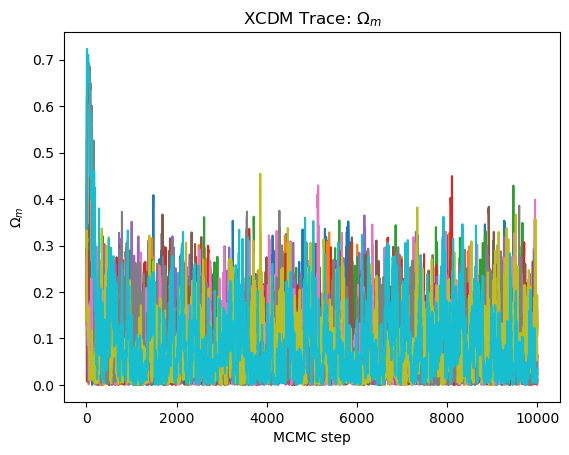

In [ ]:
fig, ax = plt.subplots()

for walker in range(10):
    ax.plot(chain_XCDM[:, walker, 0])

ax.set_xlabel("MCMC step")
ax.set_ylabel(r"$\Omega_m$")
ax.set_title(r"XCDM Trace: $\Omega_m$")

plt.show()

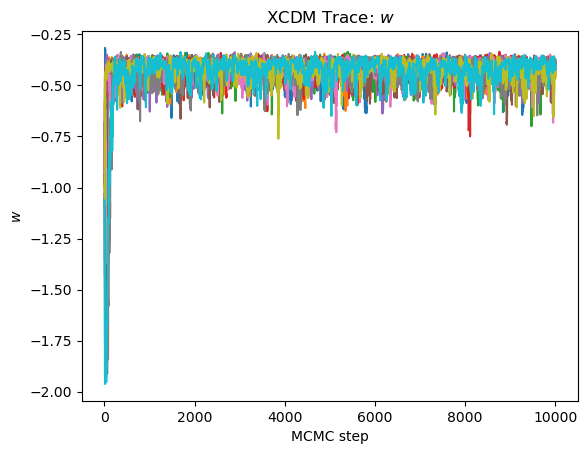

In [ ]:
fig, ax = plt.subplots()

for walker in range(10):
    ax.plot(chain_XCDM[:, walker, 1])

ax.set_xlabel("MCMC step")
ax.set_ylabel(r"$w$")
ax.set_title(r"XCDM Trace: $w$")

plt.show()

In [ ]:
tau_XCDM = sampler_XCDM.get_autocorr_time()
print(tau_XCDM)

[59.45880227 60.29738978]


In [ ]:
burn_in_XCDM = 500
samples_XCDM = sampler_XCDM.get_chain(
    discard=burn_in_XCDM,
    flat=True
)

print(samples_XCDM.shape)

(95000, 2)


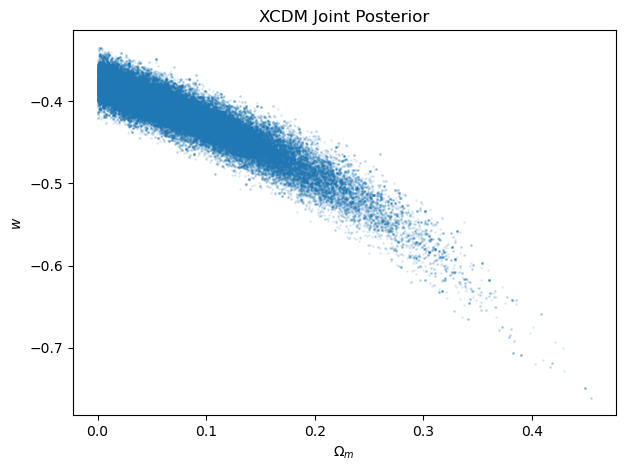

In [ ]:
plt.figure(figsize=(7, 5))

plt.scatter(
    samples_XCDM[:, 0],
    samples_XCDM[:, 1],
    s=1,
    alpha=0.1
)

plt.xlabel(r"$\Omega_m$")
plt.ylabel(r"$w$")
plt.title("XCDM Joint Posterior")

plt.show()

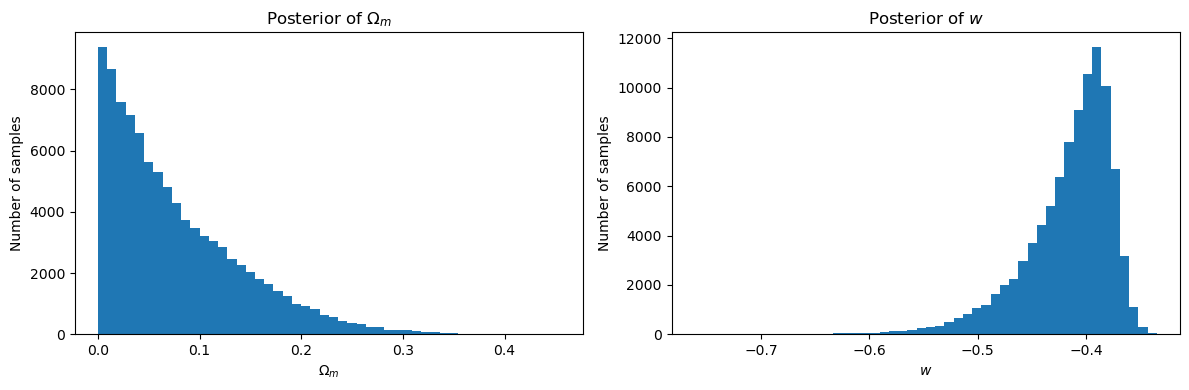

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].hist(samples_XCDM[:, 0], bins=50)
ax[0].set_xlabel(r"$\Omega_m$")
ax[0].set_ylabel("Number of samples")
ax[0].set_title(r"Posterior of $\Omega_m$")

ax[1].hist(samples_XCDM[:, 1], bins=50)
ax[1].set_xlabel(r"$w$")
ax[1].set_ylabel("Number of samples")
ax[1].set_title(r"Posterior of $w$")

plt.tight_layout()
plt.show()

In [ ]:
omega_m_median = np.median(samples_XCDM[:, 0])
omega_m_lower = np.percentile(samples_XCDM[:, 0], 16)
omega_m_upper = np.percentile(samples_XCDM[:, 0], 84)

w_median = np.median(samples_XCDM[:, 1])
w_lower = np.percentile(samples_XCDM[:, 1], 16)
w_upper = np.percentile(samples_XCDM[:, 1], 84)

print("Omega_m =", omega_m_median)
print("Omega_m 68% interval =", omega_m_lower, omega_m_upper)

print("w =", w_median)
print("w 68% interval =", w_lower, w_upper)

Omega_m = 0.05864453373206004
Omega_m 68% interval = 0.015134112797640892 0.14249081516903603
w = -0.40644092710817575
w 68% interval = -0.4532275771293674 -0.380953831026073


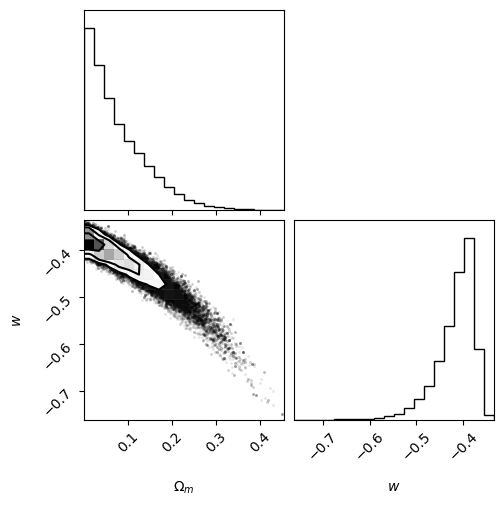

In [ ]:
import corner

fig = corner.corner(
    samples_XCDM,
    labels=[r"$\Omega_m$", r"$w$"]
)

plt.show()